In [1]:
import sympy as sp
import numpy as np
from scipy.special import ellipk
from scipy.constants import epsilon_0, mu_0
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import pandas as pd
from scipy.signal import find_peaks
from scipy.optimize import curve_fit

In [2]:
# Plotting preferences.
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman"] + plt.rcParams["font.serif"]

# Define color scheme: grey to black.
def make_colors(n,name='summer'):
    cmap = cm.get_cmap(name)
    values = np.linspace(0, 1, n)
    colors = cmap(values)
    return colors

In [3]:
"""
Physical constants. 
"""
EPS_R_SAPPHIRE = 9.6 # Sapphire dielectric constant.
EPS_R_hBN = 2.8

In [4]:
# Coplanar capacitance and inductance for center pin of resonator.
def cpw_LC(w,g,sheet_ind):
    # Half in air and half in sapphire.
    eps_eff = 0.5 * (EPS_R_SAPPHIRE + 1)

    # Elliptic modulus.
    k = w / (w + 2*g)
    m = k**2
    m_prime = 1 - m

    # Complete elliptic integrals.
    K_k = ellipk(m)
    K_kprime = ellipk(m_prime)

    # Per-unit-length quantities.
    C_per_length = 4 * epsilon_0 * eps_eff * (K_k / K_kprime)
    L_per_length = (mu_0 / 4) * (K_kprime / K_k) + sheet_ind/w # Plus sheet inductance per unit length.
    z0 = np.sqrt(L_per_length/C_per_length) # Characteristic impedance of resonator.

    print("C':", C_per_length)
    print("L':", L_per_length)
    print('Z0:',z0)

    return C_per_length, L_per_length, z0

def add_in_series(*Zs):
    return sum(Zs)

def add_in_parallel(*Zs):
    return 1/sum(1/Z for Z in Zs)

def zin_terminated_res(z0,zload,prop_constant):
    zin = z0 * (zload + z0 * np.tanh(prop_constant)) / (z0 + zload * np.tanh(prop_constant))
    return zin

def zin_unloaded_res_lamda2(z0,prop_constant):
    return z0/np.tanh(prop_constant)

def zin_unloaded_res_lamda4(z0,prop_constant):
    return z0*np.tanh(prop_constant)
    

In [5]:
# Transmission line impedance.
sheet_ind = 35e-12 # Starting with 100pH sheet inductance.
center_pin_width = 2e-6
ground_plane_gap = 60e-6

feedline_C = 20e-15 # 30fF coupling to feedline.
z_feedline = 50 # Impedance of feedline.

# Find characteristic impedance of resonator based on coplanar waveguide geometry.
C_per_length, L_per_length, z0 = cpw_LC(center_pin_width,ground_plane_gap,sheet_ind)
print(f"Characteristic impedance is: {z0}.")

C': 5.363777438185871e-11
L': 1.8599420206198138e-05
Z0: 588.8630832507185
Characteristic impedance is: 588.8630832507185.


In [6]:
"""
Estimate coupling to feedline as parallel plate capacitance. I think there is also some inductive coupling.
"""
eps_eff = 0.5 * (EPS_R_SAPPHIRE + 1) * epsilon_0

In [18]:
def plot_resonance(f, center_pin_lengths = [2000e-6],color='blue'):
    omegas = 2 * np.pi * f
    colors = make_colors(len(center_pin_lengths))
    for idx in range(len(center_pin_lengths)):
        center_pin_length = center_pin_lengths[idx]
        # color = colors[idx]
        s21_mags = []
        s21_phases = []
        for omega in omegas:

            beta = 1j*omega*np.sqrt(C_per_length*L_per_length)
            prop_constant = beta*center_pin_length

            zin = zin_unloaded_res_lamda2(z0,prop_constant)

            # Solve for impedance presented to transmission line through coupling capacitor.
            coupling_cap = 1/(1j*omega*feedline_C)
            z_coupled = add_in_series(coupling_cap,zin)

            s21 = 2*z_coupled/(2*z_coupled + z_feedline)
            s21_mags.append(10*np.log10(np.abs(s21)**2))
            s21_phases.append(np.angle(s21))

        plt.figure(1,figsize=(10,5))
        plt.plot(f/1e9,s21_mags,label=f'{np.round(center_pin_length*1e6,0)}um',color=color)
        plt.xlabel("Frequency [GHz]")
        plt.ylabel("$S_{21}$")
        plt.legend(title='Center Pin Lengths',bbox_to_anchor=(1,1))

C:\Users\emmag\AppData\Local\Temp\ipykernel_22548\1929864652.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap(name)
C:\Users\emmag\AppData\Local\Temp\ipykernel_22548\264314356.py:24: UserWarning: Ignoring specified arguments in this call because figure with num: 1 already exists
  plt.figure(1,figsize=(10,5))


Text(0.5, 1.0, 'Modelled NbN Resonator Resonances')

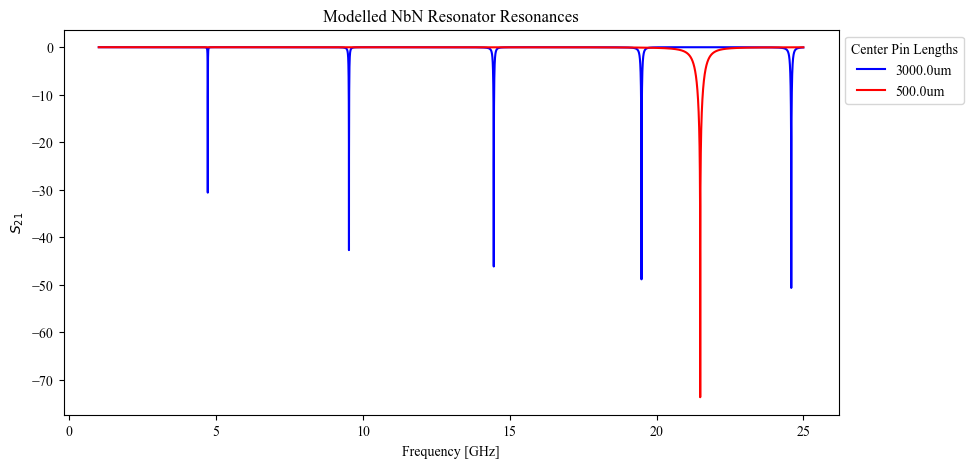

In [19]:
f=np.linspace(1e9,25e9,int(5e4))
plot_resonance(f,center_pin_lengths=[3000e-6],color='blue')
f=np.linspace(1e9,25e9,int(5e4))
plot_resonance(f,center_pin_lengths=[500e-6],color='red')
plt.title("Modelled NbN Resonator Resonances")